# Experiment 3 — Temperature Scaling for the XLM-R + TF-IDF Ensemble

**Goal:** test whether correcting probability confidence improves **macro-F1** over the existing weighted ensemble without retraining either base model or using test labels.

**Reference:** XLM-R epoch 4 (`0.9049`), TF-IDF Logistic Regression C=3 (`0.8644`); 45% XLM-R + 55% TF-IDF (`0.9141`) on 8,000 validation rows. Original ensemble public Kaggle score: `0.91071` (not a tuning target).

**Method:** fit model-specific temperature parameters by minimizing negative log-likelihood on one validation half and evaluate on the opposite half, swapping halves (2-fold cross-fitting).


In [1]:
import os, glob, json, hashlib, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import f1_score, classification_report, confusion_matrix, log_loss

SEED = 42
CLASSES = ["human", "ai", "fusion"]
L2I = {c: i for i,c in enumerate(CLASSES)}
EXPECTED_FP = "97fed7e0aa8163e74359d495ffc4a025"
OUT = Path('/kaggle/working/experiment_4_calibration_outputs' if Path('/kaggle/working').is_dir() else './experiment_4_calibration_outputs')
OUT.mkdir(parents=True, exist_ok=True)
# Provide explicit paths if multiple copies of saved predictions are attached.
TFIDF_PATH = None
XLMR_PATH = None
BASELINE_SUBMISSION_PATH = None
print('Output directory:', OUT)


Output directory: /kaggle/working/experiment_4_calibration_outputs


## 1. Reconstruct the original validation split and verify identifiers

In [2]:
def unique_file(filename, explicit=None):
    if explicit:
        p=Path(explicit)
        if not p.is_file(): raise FileNotFoundError(str(p))
        return p
    paths = sorted({str(p) for root in ('/kaggle/input','.') for p in Path(root).glob('**/'+filename)} )
    if not paths: raise FileNotFoundError(f'{filename} not found. Add the relevant Kaggle input.')
    if len(paths)>1: raise RuntimeError(f'Multiple {filename}: {paths}; set the explicit path above.')
    return Path(paths[0])

train_path = unique_file('train.csv')
DATA_DIR = train_path.parent
train = pd.read_csv(train_path, dtype={'id':str})
test = pd.read_csv(DATA_DIR/'test.csv', dtype={'id':str})
submission_template = pd.read_csv(DATA_DIR/'sample_submission.csv', dtype={'id':str})
assert train.id.is_unique and test.id.is_unique and submission_template.id.is_unique
assert len(test)==len(submission_template)==25000
assert set(test.id)==set(submission_template.id)
sub = train.sample(40000, random_state=SEED).reset_index(drop=True)
_, val = train_test_split(sub, test_size=.2, random_state=SEED,
                          stratify=sub.label+'_'+sub.lang)
val = val.reset_index(drop=True)
y = val.label.map(L2I).to_numpy(dtype=np.int64)
val_ids = val.id.astype(str).tolist(); test_ids = test.id.astype(str).tolist()
fp = hashlib.md5(','.join(val_ids).encode()).hexdigest()
assert fp==EXPECTED_FP, f'Validation split mismatch: {fp}'
assert len(val)==8000
print('Validation fingerprint:', fp, '| val:',len(val),'| test:',len(test))


Validation fingerprint: 97fed7e0aa8163e74359d495ffc4a025 | val: 8000 | test: 25000


## 2. Load the original probability archives with strict shape, label, and ID checks

In [3]:
tf_path=unique_file('tfidf_probs.npz',TFIDF_PATH)
x_path=unique_file('xlmr_probs.npz',XLMR_PATH)
print('TF-IDF:',tf_path)
print('XLM-R:',x_path)

def check_prob(p,rows,name):
    p=np.asarray(p,dtype=np.float64)
    if p.shape != (rows,3): raise ValueError(f'{name}: shape {p.shape}, expected {(rows,3)}')
    if not np.isfinite(p).all() or (p<0).any() or (p>1+1e-5).any(): raise ValueError(f'{name}: invalid probabilities')
    if not np.allclose(p.sum(axis=1),1,atol=1e-3): raise ValueError(f'{name}: row sums != 1')
    return np.clip(p,1e-12,1)

def reindex(ids,target,name):
    ids=[str(i) for i in ids]; target=[str(i) for i in target]
    if len(ids)!=len(target) or len(set(ids))!=len(ids) or set(ids)!=set(target):
        raise ValueError(f'{name}: ID mismatch')
    return pd.Index(ids).get_indexer(target)

with np.load(x_path,allow_pickle=False) as z:
    assert set(['va_ids','test_ids','classes','yva','P_va','P_te']).issubset(z.files)
    assert [str(c) for c in z['classes']]==CLASSES
    ixv=reindex(z['va_ids'],val_ids,'XLM-R validation')
    ixt=reindex(z['test_ids'],test_ids,'XLM-R test')
    P_x=check_prob(z['P_va'][ixv],len(y),'XLM-R validation')
    P_x_test=check_prob(z['P_te'][ixt],len(test),'XLM-R test')
    assert np.array_equal(z['yva'][ixv].astype(int),y)

config_candidates=[x_path.parent/'run_config.json',x_path.parent.parent/'run_config.json']
for cp in config_candidates:
    if cp.is_file():
        cfg=json.loads(cp.read_text())
        assert cfg.get('best_epoch')==4, f'Wrong XLM-R run, expected epoch 4: {cfg}'
        if cfg.get('val_id_fingerprint'):
            assert cfg['val_id_fingerprint']==fp
        print('Confirmed epoch-4 encoder via',cp)
        break
else:
    print('WARNING: no run_config.json; epoch-4 run checked via validation macro-F1 below')

with np.load(tf_path,allow_pickle=False) as z:
    assert set(['P_va','P_te','yva']).issubset(z.files)
    if 'classes' in z.files: assert [str(c) for c in z['classes']]==CLASSES
    if 'va_ids' in z.files and 'test_ids' in z.files:
        itv=reindex(z['va_ids'],val_ids,'TF-IDF validation')
        itt=reindex(z['test_ids'],test_ids,'TF-IDF test')
        P_t=check_prob(z['P_va'][itv],len(y),'TF-IDF validation')
        P_t_test=check_prob(z['P_te'][itt],len(test),'TF-IDF test')
        assert np.array_equal(z['yva'][itv].astype(int),y)
        tf_has_ids=True
    else:
        # Historical TF-IDF archive lacks IDs: identical original split & labels are necessary but not sufficient evidence.
        P_t=check_prob(z['P_va'],len(y),'TF-IDF validation')
        P_t_test=check_prob(z['P_te'],len(test),'TF-IDF test')
        assert np.array_equal(z['yva'].astype(int),y)
        tf_has_ids=False

score_x=f1_score(y,P_x.argmax(1),average='macro')
score_t=f1_score(y,P_t.argmax(1),average='macro')
score_ref=f1_score(y,(.45*P_x+.55*P_t).argmax(1),average='macro')
print(f'Original F1: TF-IDF={score_t:.4f}, XLM-R={score_x:.4f}, ensemble 45/55={score_ref:.4f}')
assert abs(score_t-.8644)<.002 and abs(score_x-.9049)<.002 and abs(score_ref-.9141)<.002, 'Wrong or misaligned notebook output detected'

# Extra test-ID confirmation from the original TF-IDF submission (recommended when archive has no test ids).
if not tf_has_ids:
    if BASELINE_SUBMISSION_PATH is not None:
        baseline_sub=Path(BASELINE_SUBMISSION_PATH)
    else:
        hits=sorted(set(glob.glob('/kaggle/input/**/sub_tfidf_baseline.csv',recursive=True)))
        baseline_sub=Path(hits[0]) if len(hits)==1 else None
    if baseline_sub is not None:
        s=pd.read_csv(baseline_sub,dtype={'id':str}).set_index('id')
        assert s.index.is_unique and set(s.index)==set(test_ids)
        actual=np.array(CLASSES)[P_t_test.argmax(1)]
        assert np.array_equal(s.loc[test_ids,'label'].to_numpy(),actual), 'TF-IDF test ordering does not match saved baseline submission'
        print('TF-IDF test order verified against baseline submission by ID')
    else:
        print('WARNING: TF-IDF archive lacks IDs and baseline submission unavailable; test ordering assumed from original notebook.')


TF-IDF: /kaggle/input/notebooks/lilialania/notebook8a3d02c74f/outputs_step1/tfidf_probs.npz
XLM-R: /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/xlmr_probs.npz
Confirmed epoch-4 encoder via /kaggle/input/notebooks/lilialania/notebook6b81f5d1b5/encoder_outputs/run_config.json
Original F1: TF-IDF=0.8644, XLM-R=0.9049, ensemble 45/55=0.9141
TF-IDF test order verified against baseline submission by ID


## 3. Calibrate with temperature scaling — out-of-fold evaluation

Temperature is fitted using *labeled validation data*, never test labels. On each fold, fit T using only the other fold; report macro-F1 only on held-out rows. Two variants are evaluated with **predefined** weights: calibrated 50/50 and calibrated 45/55.

In [4]:
EPS=1e-12

def temp_scale(P,T):
    logits=np.log(np.clip(P,EPS,1.0))/float(T)
    logits=logits-logits.max(axis=1,keepdims=True)
    Q=np.exp(logits)
    return Q/Q.sum(axis=1,keepdims=True)

def nll(P,y):
    return -np.log(np.maximum(P[np.arange(len(y)),y],EPS)).mean()

def fit_temp(P,y):
    opt=minimize_scalar(lambda logT:nll(temp_scale(P,np.exp(logT)),y),
                        bounds=(np.log(.05),np.log(20.)),method='bounded',options={'xatol':1e-6})
    if not opt.success: raise RuntimeError(opt.message)
    return float(np.exp(opt.x))

folds=StratifiedKFold(n_splits=2,shuffle=True,random_state=SEED)
Pcx=np.full_like(P_x,np.nan); Pct=np.full_like(P_t,np.nan)
rows=[]
for fold,(fit_idx,eval_idx) in enumerate(folds.split(np.zeros(len(y)),y),1):
    tx=fit_temp(P_x[fit_idx],y[fit_idx]); tt=fit_temp(P_t[fit_idx],y[fit_idx])
    Pcx[eval_idx]=temp_scale(P_x[eval_idx],tx)
    Pct[eval_idx]=temp_scale(P_t[eval_idx],tt)
    rows.append({'fold':fold,'n_fit':len(fit_idx),'n_eval':len(eval_idx),
                 'T_xlmr':tx,'T_tfidf':tt,
                 'xlmr_NLL_raw':nll(P_x[eval_idx],y[eval_idx]),
                 'xlmr_NLL_cal':nll(Pcx[eval_idx],y[eval_idx]),
                 'tfidf_NLL_raw':nll(P_t[eval_idx],y[eval_idx]),
                 'tfidf_NLL_cal':nll(Pct[eval_idx],y[eval_idx])})
assert np.isfinite(Pcx).all() and np.isfinite(Pct).all()
fold_table=pd.DataFrame(rows)
display(fold_table.round(4))


,fold,n_fit,n_eval,T_xlmr,T_tfidf,xlmr_NLL_raw,xlmr_NLL_cal,tfidf_NLL_raw,tfidf_NLL_cal
0,1,4000,4000,2.4067,0.7442,0.4091,0.2359,0.2837,0.2770
1,2,4000,4000,2.3997,0.7936,0.4121,0.2377,0.2724,0.2617


## 4. Compare original and calibrated blends on the same 8,000 validation rows

In [5]:
def summary(name,P):
    yh=P.argmax(1)
    return {'model':name,'macro_f1':f1_score(y,yh,average='macro'),
            'accuracy':float((y==yh).mean()),'nll':nll(P,y),
            **{f'{c}_f1':f1_score(y,yh,labels=[j],average='macro',zero_division=0) for j,c in enumerate(CLASSES)}}

reference_4555=.45*P_x+.55*P_t
raw_5050=.5*P_x+.5*P_t
cal_4555=.45*Pcx+.55*Pct
cal_5050=.5*Pcx+.5*Pct
results=pd.DataFrame([
 summary('Original XLM-R',P_x),
 summary('Original TF-IDF',P_t),
 summary('Raw 45/55 (reference)',reference_4555),
 summary('Raw 50/50',raw_5050),
 summary('Calibrated 45/55 (OOF)',cal_4555),
 summary('Calibrated 50/50 (OOF)',cal_5050),
]).sort_values('macro_f1',ascending=False)
display(results.round(5))
results.to_csv(OUT/'model_comparison.csv',index=False)
for name,p in [('calibrated 45/55',cal_4555),('calibrated 50/50',cal_5050)]:
    pr=p.argmax(1)
    print('\n',name, '\n',classification_report(y,pr,target_names=CLASSES,digits=4))
    print('Confusion matrix, rows/columns in class order:', CLASSES,'\n',confusion_matrix(y,pr,labels=[0,1,2]))

baseline=f1_score(y,reference_4555.argmax(1),average='macro')
print('Δ calibrated 45/55 vs raw 45/55:',round(f1_score(y,cal_4555.argmax(1),average='macro')-baseline,5))
print('Δ calibrated 50/50 vs raw 45/55:',round(f1_score(y,cal_5050.argmax(1),average='macro')-baseline,5))


,model,macro_f1,accuracy,nll,human_f1,ai_f1,fusion_f1
5,Calibrated 50/50 (OOF),0.91803,0.93162,0.19605,0.87077,0.98897,0.89434
2,Raw 45/55 (reference),0.91409,0.92838,0.19730,0.86420,0.98802,0.89006
4,Calibrated 45/55 (OOF),0.91190,0.92650,0.19849,0.86269,0.99047,0.88256
3,Raw 50/50,0.91117,0.92575,0.19370,0.86085,0.98585,0.88682
0,Original XLM-R,0.90486,0.92050,0.41061,0.85032,0.98409,0.88016
1,Original TF-IDF,0.86444,0.88575,0.27804,0.80077,0.98624,0.80631



 calibrated 45/55 
               precision    recall  f1-score   support

       human     0.8605    0.8649    0.8627      1954
          ai     0.9833    0.9978    0.9905      3592
      fusion     0.8942    0.8712    0.8826      2454

    accuracy                         0.9265      8000
   macro avg     0.9126    0.9113    0.9119      8000
weighted avg     0.9260    0.9265    0.9262      8000

Confusion matrix, rows/columns in class order: ['human', 'ai', 'fusion'] 
 [[1690   16  248]
 [   3 3584    5]
 [ 271   45 2138]]

 calibrated 50/50 
               precision    recall  f1-score   support

       human     0.8925    0.8501    0.8708      1954
          ai     0.9795    0.9986    0.9890      3592
      fusion     0.8902    0.8985    0.8943      2454

    accuracy                         0.9316      8000
   macro avg     0.9207    0.9157    0.9180      8000
weighted avg     0.9309    0.9316    0.9311      8000

Confusion matrix, rows/columns in class order: ['human', 'ai', 'fu

## 5. Paired uncertainty analysis and model selection

Calibrated 45/55: bootstrap 95% interval for Δ macro-F1 vs raw 45/55: [-0.00643  0.00267]
Calibrated 50/50: bootstrap 95% interval for Δ macro-F1 vs raw 45/55: [0.00068 0.00694]


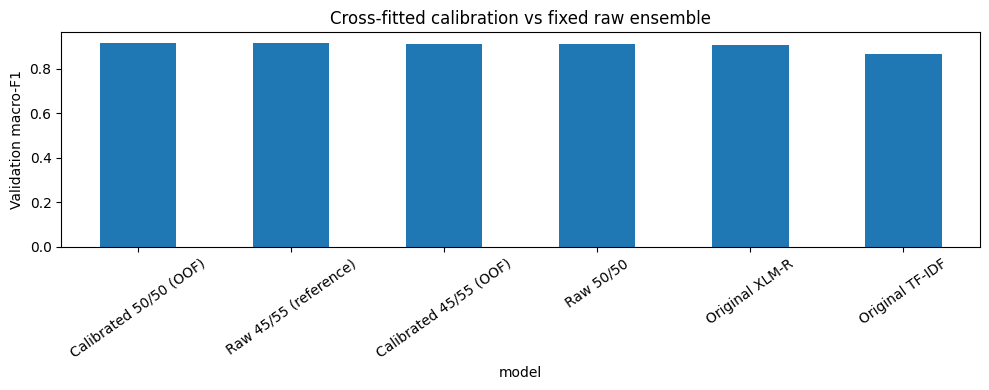

In [6]:
rng=np.random.default_rng(SEED)
B=1000
for name,P in [('Calibrated 45/55',cal_4555),('Calibrated 50/50',cal_5050)]:
    diffs=[]
    pred=P.argmax(1); baseline_pred=reference_4555.argmax(1)
    for _ in range(B):
        ix=rng.integers(0,len(y),len(y))
        diffs.append(f1_score(y[ix],pred[ix],average='macro')-f1_score(y[ix],baseline_pred[ix],average='macro'))
    print(f'{name}: bootstrap 95% interval for Δ macro-F1 vs raw 45/55:',np.round(np.percentile(diffs,[2.5,97.5]),5))

results.plot(kind='bar',x='model',y='macro_f1',legend=False,figsize=(10,4),rot=35)
plt.ylabel('Validation macro-F1');plt.title('Cross-fitted calibration vs fixed raw ensemble');plt.tight_layout()
plt.savefig(OUT/'comparison.png',dpi=170);plt.show()


## 6. Fit final temperatures on all validation labels and create Kaggle submissions

At submission time temperature scalars are fitted on all 8,000 validation labels. Base model weights remain unchanged.

In [7]:
Tx_full=fit_temp(P_x,y)
Tt_full=fit_temp(P_t,y)
print(f'Final temperatures (all validation): XLM-R T={Tx_full:.5f}, TF-IDF T={Tt_full:.5f}')
Qx_test=temp_scale(P_x_test,Tx_full)
Qt_test=temp_scale(P_t_test,Tt_full)

def save_submission(P,name):
    pred=np.array(CLASSES)[P.argmax(1)]
    s=pd.DataFrame({'id':test_ids,'label':pred}).set_index('id').loc[submission_template.id].reset_index()
    assert len(s)==25000 and list(s.columns)==['id','label'] and s.id.is_unique
    assert s.id.tolist()==submission_template.id.tolist()
    assert set(s.label).issubset(set(CLASSES)) and not s.isna().any().any()
    path=OUT/name
    s.to_csv(path,index=False)
    print('Saved',path,'| label shares (predictions, NOT true test distribution):',s.label.value_counts(normalize=True).round(3).to_dict())
    return s

sub_cal4555=save_submission(.45*Qx_test+.55*Qt_test,'sub_calibrated_4555.csv')
sub_cal5050=save_submission(.5*Qx_test+.5*Qt_test,'sub_calibrated_5050.csv')
sub_raw=save_submission(.45*P_x_test+.55*P_t_test,'sub_reference_4555.csv')
print('Predictions changed vs raw reference:',
      int((sub_cal4555.label!=sub_raw.label).sum()),'for 45/55,',
      int((sub_cal5050.label!=sub_raw.label).sum()),'for 50/50')
config={'seed':SEED,'validation_fingerprint':fp,'classes':CLASSES,
        'sources':{'tfidf':str(tf_path),'xlmr':str(x_path)},
        'temperatures':{'xlmr':Tx_full,'tfidf':Tt_full},
        'weights':{'calibrated_4555':{'xlmr':.45,'tfidf':.55},'calibrated_5050':{'xlmr':.5,'tfidf':.5}},
        'evaluation':'2-fold stratified cross-fitting of temperatures on the original validation; checkpoint and old 45/55 weight were selected on this validation earlier',
        'kaggle_test_labels_used':False}
(OUT/'calibration_config.json').write_text(json.dumps(config,indent=2))
np.savez_compressed(OUT/'calibration_probs.npz',va_ids=np.asarray(val_ids),test_ids=np.asarray(test_ids),
                    yva=y,classes=np.asarray(CLASSES),P_va_cal4555_oof=cal_4555,
                    P_va_cal5050_oof=cal_5050,P_te_cal4555=.45*Qx_test+.55*Qt_test,
                    P_te_cal5050=.5*Qx_test+.5*Qt_test)
print('All outputs:',*[str(p.name) for p in sorted(OUT.iterdir())],sep='\n  ')


Final temperatures (all validation): XLM-R T=2.40319, TF-IDF T=0.76921
Saved /kaggle/working/experiment_4_calibration_outputs/sub_calibrated_4555.csv | label shares (predictions, NOT true test distribution): {'ai': 0.523, 'human': 0.248, 'fusion': 0.23}
Saved /kaggle/working/experiment_4_calibration_outputs/sub_calibrated_5050.csv | label shares (predictions, NOT true test distribution): {'ai': 0.525, 'fusion': 0.238, 'human': 0.237}
Saved /kaggle/working/experiment_4_calibration_outputs/sub_reference_4555.csv | label shares (predictions, NOT true test distribution): {'ai': 0.526, 'fusion': 0.238, 'human': 0.236}
Predictions changed vs raw reference: 663 for 45/55, 318 for 50/50
All outputs:
  calibration_config.json
  calibration_probs.npz
  comparison.png
  model_comparison.csv
  sub_calibrated_4555.csv
  sub_calibrated_5050.csv
  sub_reference_4555.csv
